# Generate a smile in one step with NUOX

Ordinary flow matching learns a velocity field that transports Gaussian noise into a smile through many small steps. Here we **distill that flow into a one-step generator**, while using NUOX to keep its instantaneous velocity close to the original field.

The workflow is **define an endpoint loss → define a velocity constraint → add NUOX to Optax**. The notebook writes out those pieces; `smile.py` handles the small MLP, data, training loops, and plots.

*Saved outputs are from the default CPU run. Run all to reproduce the experiment.*

## 1. Set up

**Colab:** open this notebook, select a **CPU or T4 GPU** runtime, and run all. When prompted, upload **`smile_tutorial.zip`**. Setup loads the included helpers and smile data, installs the dependencies, and selects the available device. If Colab requests a restart after installation, restart the session once and run all again.

**Local Jupyter / VS Code:** keep this notebook, `smile.py`, `setup_tutorial.py`, and `smiley_face.json` together. Use Python 3.11–3.13. In the NUOX repository, place them in `tutorials/flow_matching`.

Both models train from scratch. There are no model downloads or saved checkpoints to find. Start with the defaults below; compilation and installation add first-run overhead.

In [1]:
#@title Setup — run once before importing JAX
from pathlib import Path
import sys

folder = Path("tutorials/flow_matching") if Path("tutorials/flow_matching").is_dir() else Path(".")
helpers = ("setup_tutorial.py", "smile.py", "smiley_face.json")
if not all((folder / name).exists() for name in helpers):
    from google.colab import files
    from zipfile import ZipFile
    with ZipFile(next(iter(files.upload()))) as bundle:
        for name in helpers:
            (folder / name).write_bytes(bundle.read(f"flow_matching/{name}"))
sys.path.insert(0, str(folder.resolve()))
from setup_tutorial import setup
setup()  # CPU automatically; GPU when one is available.

Preparing CPU dependencies…
Ready. The smile data is included; both models train from scratch.


In [2]:
import jax
import jax.numpy as jnp
import optax
from nuox import make_project_grad
from nuox.linalg import lstsq_lsmr
import smile

## 2. Learn an ordinary flow

Our data is the supplied 300-point smile. We use the convention **data at $t=0$, noise at $t=1$**. Ordinary flow matching regresses $\epsilon-x$ at $z_t=(1-t)x+t\epsilon$, using independent data and Gaussian noise.

`velocity(params, z, r, t)` represents an average velocity over an interval. The ordinary model is trained only on its diagonal, `r=t`. We first train that model and freeze a copy as the teacher. Both training stages use a fixed exponential moving average (decay 0.99).

In [3]:
teacher_steps, nuox_steps = 8000, 4000
initial, velocity = smile.model(width=128, seed=0)
teacher, teacher_history = smile.train_flow(velocity, initial, steps=teacher_steps)
paths = smile.make_paths(velocity, teacher, count=4096, steps=128)

ERROR:2026-11-05 13:31:01,594:jax._src.xla_bridge:475: Jax plugin configuration error: Exception when calling jax_plugins.xla_cuda12.initialize()
Traceback (most recent call last):
  File "/dtu/p1/hroy/projected-constraints/grad-proj/lib/python3.12/site-packages/jax/_src/xla_bridge.py", line 473, in discover_pjrt_plugins
    plugin_module.initialize()
  File "/dtu/p1/hroy/projected-constraints/grad-proj/lib/python3.12/site-packages/jax_plugins/xla_cuda12/__init__.py", line 328, in initialize
    _check_cuda_versions(raise_on_first_error=True)
  File "/dtu/p1/hroy/projected-constraints/grad-proj/lib/python3.12/site-packages/jax_plugins/xla_cuda12/__init__.py", line 285, in _check_cuda_versions
    local_device_count = cuda_versions.cuda_device_count()
                         ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
RuntimeError: jaxlib/cuda/versions_helpers.cc:113: operation cuInit(0) failed: Unknown CUDA error 303; cuGetErrorName failed. This probably means that JAX was unable to load the CU

Ordinary flow matching: 8,000 updates (the first block compiles)…
Ordinary flow matching finished in 9.6s, including compilation.
Caching 4,096 teacher trajectories with 128 Euler steps…
Trajectory cache ready in 1.0s.


## 3. Define the one-step learning objective

From a teacher trajectory, choose two times $r<t$ and their states $X_r^T,X_t^T$. Train the student to reach the earlier state in **one** prediction:

$$\mathcal L(\theta)=\mathbb E\left[\tfrac12\left\|
X_t^T-(t-r)u_\theta(X_t^T,r,t)-X_r^T\right\|^2\right].$$

The helper samples interior, noise-start, data-end, and full intervals in equal proportions. The cached teacher trajectories provide fixed targets; training differentiates the student's prediction.

In [4]:
def loss(params, batch):
    z, r, t, target = batch
    endpoint = z - (t-r) * velocity(params, z, r, t)
    return jnp.mean((endpoint-target)**2)

## 4. Define the constraint

Preserve the teacher's **instantaneous** velocity at sampled states:

$$\min_\theta \mathcal L(\theta)\quad\text{subject to}\quad
c(\theta)=\frac{1}{\sqrt{2N}}\operatorname{vec}\left[
 u_\theta(z_i,t_i,t_i)-v_T(z_i,t_i)\right]_{i=1}^{N}=0.$$

The residual stacks both velocity components. Its Euclidean norm equals their RMS error. The constraint fixes the diagonal **$r=t$**; the one-step generator queries **$(r,t)=(0,1)$**, so its output can improve even though it preserves the instantaneous field approximately.

In [5]:
def constraint(params, z, t, reference):
    residual = velocity(params, z, t, t) - reference
    return residual.ravel() / jnp.sqrt(z.size)

## 5. Add NUOX to Optax

Clip the objective gradient, apply Adam, project with NUOX, then apply the negative learning-rate scale. `rho` sets the intended correction fraction; because `-lr` comes last, use `gamma=rho/lr`. Projection is active from the first update.

The damped, finite-iteration least-squares solve uses Jacobian products. We will measure the remaining velocity error on independent states after training.

In [6]:
lr, rho = 3e-4, 0.2
project = make_project_grad(
    constraint, wm_epochs=-1, num_batches=1, gamma=rho/lr,
    least_squares_solver=lstsq_lsmr(maxiter=32, damp=0.01, atol=1e-7, btol=1e-7),
)
optimizer = optax.chain(
    optax.clip_by_global_norm(1.0), optax.scale_by_adam(), project, optax.scale(-lr)
)

## 6. Train the student

Start from the ordinary FM weights. Draw fresh constraint states once per update, and keep them fixed throughout NUOX's inner solve. The target velocities come from the frozen teacher. The training helper calls this exact update and averages its iterates.

In [7]:
@jax.jit
def step(params, state, index, teacher, paths):
    batch = smile.trajectory_batch(paths, index, n=256)
    value, gradient = jax.value_and_grad(loss)(params, batch)
    z, t = smile.velocity_batch(index, n=32)
    reference = velocity(teacher, z, t, t)
    updates, state = optimizer.update(gradient, state, (params, (z, t, reference), {}))
    return optax.apply_updates(params, updates), state, value

In [8]:
student, history = smile.train(
    step, optimizer, teacher, nuox_steps, teacher, paths, label="NUOX distillation"
)

NUOX distillation: 4,000 updates (the first block compiles)…
NUOX distillation finished in 91.4s, including compilation.


## 7. Generate in one network call

A new Gaussian noise sample becomes $x=\epsilon-u_\theta(\epsilon,0,1)$. Sampling is just the following network evaluation and subtraction; NUOX is used during training.

In [9]:
@jax.jit
def one_step(params, noise):
    t = jnp.ones((len(noise), 1))
    return noise - velocity(params, noise, jnp.zeros_like(t), t)

## 8. Compare with ordinary flow matching

All step counts and both models use the same 4,096 new test noises. The panels show their first 2,048 outputs, unfiltered, with shared axes. **SW₁** is sliced Wasserstein-1 distance to the complete 300-point target; lower is better. Rows show Flow Matching and NUOX; columns use 1, 2, 4, and 8 network evaluations. The complete target appears in a separate figure. The quality curve below also includes 16 and 128 evaluations.

NUOX receives additional training on the teacher trajectories. This comparison illustrates the resulting one-step workflow; it does not isolate the benefit of the constraint from the distillation objective.

In [ ]:
samples, scores = smile.evaluate(velocity, teacher, student, one_step)
_ = smile.plot_target(samples["target"])
_ = smile.plot_comparison(samples, scores)
ratio = scores["fm"][0] / scores["nuox"][0]
print(f"One-step SW₁: ordinary FM {scores['fm'][0]:.4f} → NUOX {scores['nuox'][0]:.4f}")
print(f"{ratio:.1f}× lower one-step error on this test draw.")
print(f"Held-out velocity drift: {100*scores['velocity_relative_error']:.2f}%")

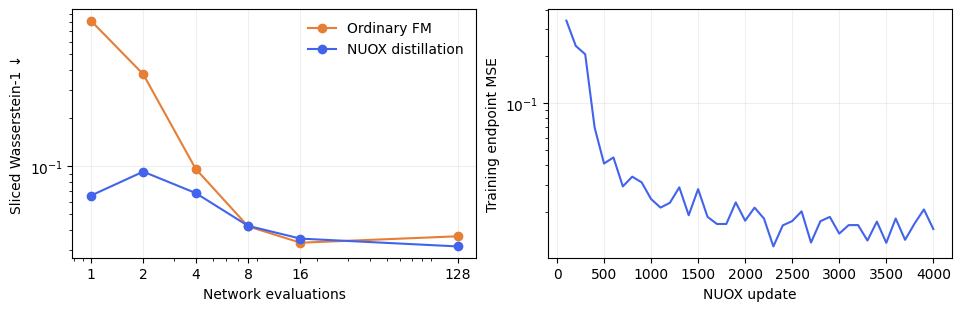

In [11]:
_ = smile.plot_quality(scores, history)

The right-hand curve shows the student's minibatch endpoint loss. The velocity diagnostic is the relative error against the teacher on 4,096 independent interpolation states, evaluated at the final averaged weights. Constraints are enforced approximately: damping, changing collocation states, finite iterations, nonlinear updates, and averaging all contribute to the residual.

## 9. Explore

Change `steps` below to compare one-, two-, or few-step generation without retraining. To change the model or training budget, edit the settings near the top and run all again; no files or checkpoints need to be cleared.

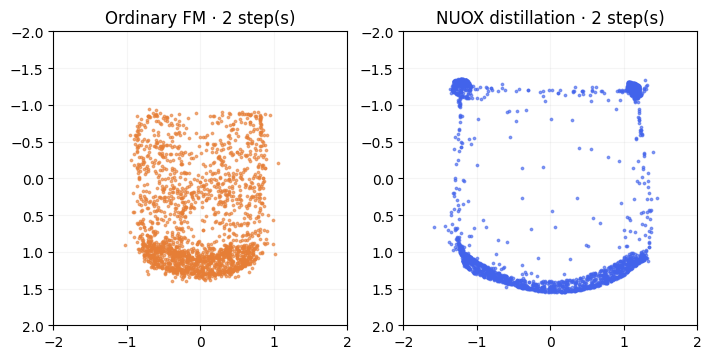

In [12]:
steps = 2  # Try 1, 2, 4, 8, or 16.
_ = smile.show_steps(velocity, teacher, student, steps=steps)

**Data:** the original 300 ordered smile points from Alec Helbling and Polo Chau's [Diffusion Explorer](https://github.com/helblazer811/Diffusion-Explorer/tree/43cea55f5553782488d53bb4056efb6035e14cbd), described in [A Visual Introduction to Rectified Flows](https://alechelbling.com/blog/rectified-flow/). Coordinates and duplicate rows are preserved; the y-axis is inverted to match screen coordinates.

[NUOX source and documentation](https://github.com/h-roy/nuox)